# November Check-In

**Goal (from our README):** find the Green Line stations most affected by Red Sox, Celtics and Bruins home games, and estimate the delays and demand that games cause.

**Data**
- Green Line headways (time between trains), 2024, cleaned in `cleaning-mbta-data.ipynb`
- Home game schedules with start times, from `scraping-boston-sports.ipynb`
- MBTA gated station entries (people tapping in), 2024
- Hourly Boston weather, 2024 (Open-Meteo historical archive)

**What's in this notebook**
1. **Delays**: how long riders wait on game nights vs normal nights
2. **Most affected stations**: which stations change after a game, with a test to rule out chance
3. **Demand**: how many people enter the venue stations, and how crowded the trains get
4. **Model**: one linear regression, fit at every station, that estimates the extra wait a game causes, with t-tests, F-tests and a multiple-testing correction, tested on days it hasn't seen

In [1]:
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
from pandas.tseries.holiday import USFederalHolidayCalendar

rng = np.random.default_rng(506)
warnings.filterwarnings('ignore')

def mean_absolute_error(actual, predicted):
    return np.mean(np.abs(np.asarray(actual) - np.asarray(predicted)))

## Measuring delay: expected wait
The median time between trains misses **bunching**. Trains that come 2, 10, 2, 10 minutes apart still average 6 minutes, but most riders arrive during a 10-minute gap and wait longer.

So we use the average wait for a rider who shows up at a random time:

$$\text{expected wait} = \frac{\text{mean}(h^2)}{2 \times \text{mean}(h)}$$

where $h$ is the time between trains.

| Trains | Average gap | Expected wait |
|---|---|---|
| exactly every 6 min | 6 min | 3.0 min |
| alternating 2 and 10 min | 6 min | 4.3 min |

The expected wait goes up when trains come **less often** or **less evenly**, which is what crowds cause. We calculate it for every station, direction, day and hour.

In [2]:
keys = ['service_date', 'parent_station', 'direction_id', 'hour']
parts, route_counts, stop_names = [], [], []
for chunk in pd.read_csv('data/green_headways_clean.csv', chunksize=1_500_000,
                         usecols=keys + ['headway_min', 'route_id', 'stop_name']):
    chunk['h2'] = chunk['headway_min'] ** 2
    parts.append(chunk.groupby(keys).agg(trains=('headway_min', 'size'),
                                         sum_h=('headway_min', 'sum'),
                                         sum_h2=('h2', 'sum')))
    route_counts.append(chunk[['parent_station', 'route_id']].value_counts())
    stop_names.append(chunk[['parent_station', 'stop_name']].drop_duplicates())

hourly = pd.concat(parts).groupby(level=keys).sum().reset_index()
hourly['service_date'] = pd.to_datetime(hourly['service_date'])
hourly['wait'] = hourly['sum_h2'] / (2 * hourly['sum_h'])
print('station-direction-hours:', len(hourly))

station-direction-hours: 896656


In [3]:
# station names, and which branch each station is on
# stations where one branch makes up 80%+ of trains get that branch, otherwise 'Trunk'
names = pd.concat(stop_names).drop_duplicates('parent_station').set_index('parent_station')['stop_name']
counts = pd.concat(route_counts).groupby(level=[0, 1]).sum()
share = counts / counts.groupby(level=0).transform('sum')
top = share.groupby(level=0).idxmax().str[1]
branch = top.where(share.groupby(level=0).max() >= 0.8, 'Trunk')
branch.value_counts()

count
Green-B    15
Green-E    14
Green-D    14
Trunk      13
Green-C    12
Name: count, dtype: int64

## Remove shutdown days and thin hours
- **Shutdown days**: the same station-days found in `cleaning-mbta-data.ipynb`. Planned diversions would look like huge delays.
- **Hours with fewer than 3 trains**: one or two gaps is too few to estimate a wait.

In [4]:
bad_days = pd.read_csv('data/shutdown_days.csv', parse_dates=['service_date'])
rows_before = len(hourly)
hourly = hourly.merge(bad_days, on=['parent_station', 'service_date'], how='left')
hourly = hourly[hourly['bad'].isna()].drop(columns='bad')
print('removed for shutdowns:', rows_before - len(hourly))

rows_before = len(hourly)
hourly = hourly[(hourly['trains'] >= 3) & (hourly['hour'] >= 5) & (hourly['hour'] <= 25)].copy()
print('removed for under 3 trains:', rows_before - len(hourly))

hourly['stop_name'] = hourly['parent_station'].map(names)
hourly['branch'] = hourly['parent_station'].map(branch)
hourly['day_of_week'] = hourly['service_date'].dt.day_of_week
hourly['weekday'] = hourly['day_of_week'] < 5
hourly['month'] = hourly['service_date'].dt.month
print('rows left:', len(hourly))
print('stations:', hourly['parent_station'].nunique(), ' days:', hourly['service_date'].nunique())
hourly['wait'].describe().round(2)

removed for shutdowns: 8505
removed for under 3 trains: 32820
rows left: 855331
stations: 66  days: 366


count    855331.00
mean          5.53
std           2.12
min           0.46
25%           4.40
50%           5.38
75%           6.49
max          29.02
Name: wait, dtype: float64

## Label game windows
Each hour gets a label based on the game's start time:

| Window | Hours | For a 7pm game |
|---|---|---|
| pre | 2 hours before the start | 5-7pm |
| during | the start hour and the next | 7-9pm |
| post | hours 2-3 after the start | 9-11pm |

We chose the post window from the ridership data below: entries at Kenmore and North Station peak at 9:30-10pm on game nights. Fenway and TD Garden get separate labels.

In [5]:
games = pd.concat([
    pd.read_csv('data/redsox_2024_home_games.csv'),
    pd.read_csv('data/celtics_2024_home_games.csv'),
    pd.read_csv('data/bruins_2024_home_games.csv'),
], ignore_index=True)
games['service_date'] = pd.to_datetime(games['date'])
games['start_hour'] = pd.to_datetime(games['start_time']).dt.hour
games['venue'] = np.where(games['team'] == 'Red Sox', 'fenway', 'garden')

window_by_hour = {-2: 'pre', -1: 'pre', 0: 'during', 1: 'during', 2: 'post', 3: 'post'}
windows = {'fenway': window_by_hour, 'garden': window_by_hour}

for v in ['fenway', 'garden']:
    starts = games[games['venue'] == v].groupby('service_date')['start_hour'].min().rename(v + '_start')
    hourly = hourly.merge(starts, on='service_date', how='left')
    hours_from_start = hourly['hour'] - hourly[v + '_start']
    hourly[v + '_window'] = hours_from_start.map(windows[v]).fillna('none')

hourly['any_game'] = hourly['fenway_start'].notna() | hourly['garden_start'].notna()
pd.crosstab(hourly['fenway_window'], hourly['garden_window'])

garden_window,during,none,post,pre
fenway_window,,,,
during,2047,18159,0,0
none,23822,723765,23672,23416
post,0,17770,2048,384
pre,0,18199,0,2049


## Add weather, holidays and game type
Things other than games can change service, so the model accounts for them:
- **Weather** (hourly, Boston, from the Open-Meteo historical weather archive): **rain** (0.01+ inches in the hour), **snow**, and **temperature**
- **Holidays**: US federal holidays run a different schedule. They're also left out of the normal nights.
- **Night vs day games**: games starting at 5pm or later are **night** games. Day games let out in the afternoon, when service and crowds are different, so they get their own effect.

In [11]:
weather = pd.read_csv('data/boston_weather_2024_hourly.csv', parse_dates=['time'])
weather['service_date'] = weather['time'].dt.normalize()
weather['hour'] = weather['time'].dt.hour
# hours after midnight belong to the previous service day (24 = midnight, 25 = 1am), like the headway data
late = weather['hour'] < 3
weather.loc[late, 'service_date'] -= pd.Timedelta(days=1)
weather.loc[late, 'hour'] += 24
weather['rain'] = (weather['rain (inch)'] >= 0.01).astype(int)
weather['snow'] = (weather['snowfall (inch)'] > 0).astype(int)
hourly = hourly.merge(weather[['service_date', 'hour', 'temperature_2m (°F)', 'rain', 'snow']], on=['service_date', 'hour'], how='left')

holidays = USFederalHolidayCalendar().holidays('2024-01-01', '2024-12-31')
hourly['holiday'] = hourly['service_date'].isin(holidays).astype(int)

# game term = window + night/day, e.g. 'post_night'
for v in ['fenway', 'garden']:
    kind = np.where(hourly[v + '_start'] >= 17, 'night', 'day')
    hourly[v + '_term'] = np.where(hourly[v + '_window'] == 'none', 'none', hourly[v + '_window'] + '_' + kind)

print('hours with rain:', round(100 * hourly['rain'].mean(), 1), '%')
print('holidays:', len(holidays))
pd.crosstab(hourly['fenway_term'], hourly['garden_term'])

hours with rain: 8.0 %
holidays: 11


garden_term,during_day,during_night,none,post_day,post_night,pre_day,pre_night
fenway_term,,,,,,,
during_day,255,0,6735,0,0,0,0
during_night,0,1792,11424,0,0,0,0
none,3784,20038,723765,3771,19901,3771,19645
post_day,0,0,6342,256,0,0,384
post_night,0,0,11428,0,1792,0,0
pre_day,0,0,6741,0,0,256,0
pre_night,0,0,11458,0,0,0,1793


## Game nights vs normal nights
To compare like with like:
- **Game nights**: weekday games starting at 7pm, so the hours line up on the clock
- **Normal nights**: weekdays with no game at either venue and no holiday, in the same months as that team's season

Weekends run a different schedule, so they're left out here. The model later uses every game.

In [12]:
def get_dates(venue):
    g = games[(games['venue'] == venue) & (games['start_hour'] == 19) & (games['service_date'].dt.day_of_week < 5)]
    season_months = games.loc[games['venue'] == venue, 'service_date'].dt.month.unique()
    normal = hourly.loc[hourly['weekday'] & ~hourly['any_game'] & hourly['month'].isin(season_months) & (hourly['holiday'] == 0), 'service_date']
    return g['service_date'].unique(), normal.unique()

for v in ['fenway', 'garden']:
    game_dates, normal_dates = get_dates(v)
    print(v, '-', len(game_dates), 'game nights,', len(normal_dates), 'normal nights')

fenway - 45 game nights, 62 normal nights
garden - 68 game nights, 105 normal nights


## Plot: a night at the venue stations
- **Top**: expected wait. **Bottom**: trains per hour, which shows *why* the wait changes.
- **Shaded bands**: 95% confidence intervals (we resample whole nights 1,000 times), so small wiggles don't look like real effects.
- **Why a line plot**: hours are in order, so you can see the gap open and close around the game. The y-axis starts at 0 so differences aren't exaggerated.

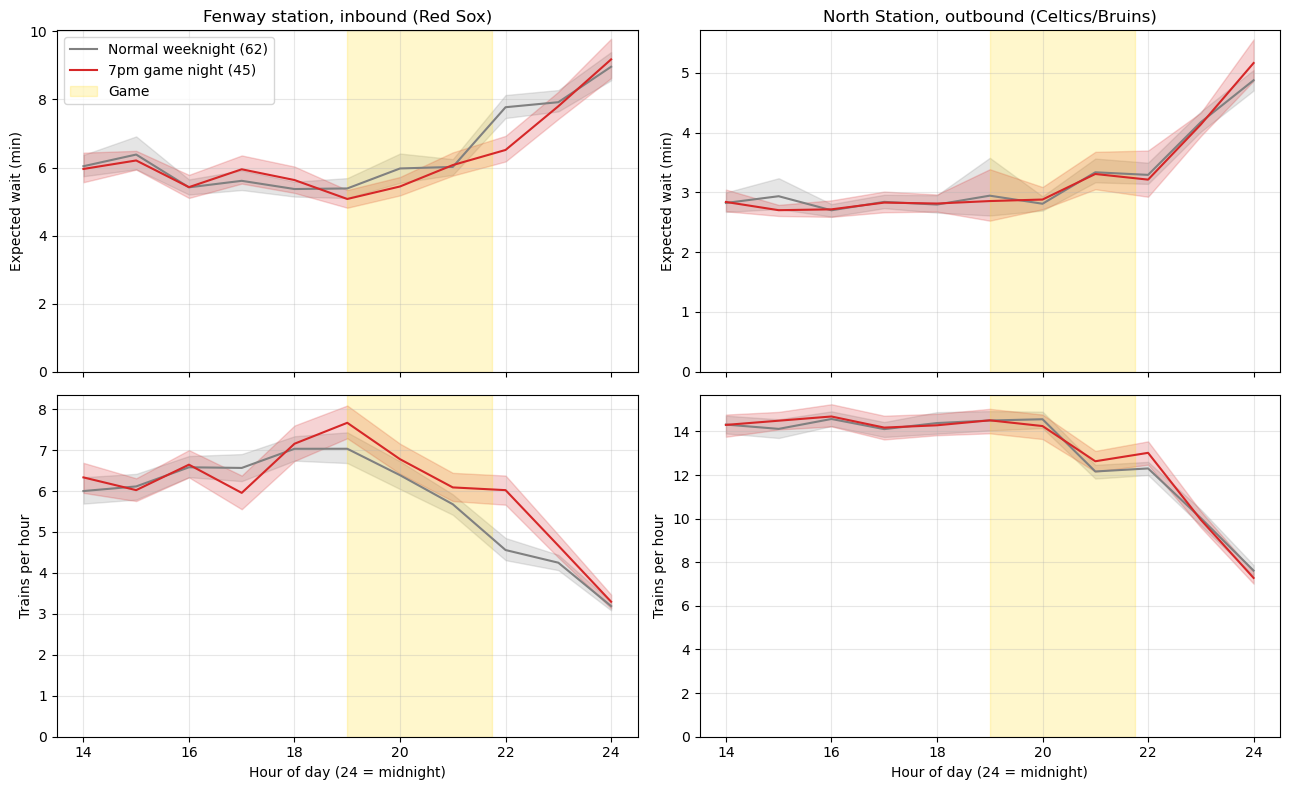

In [13]:
def by_hour_with_ci(df, col, dates, time_col='hour'):
    # mean of col for each hour across the given nights, with a bootstrap 95% CI
    table = df[df['service_date'].isin(dates)].pivot_table(index='service_date', columns=time_col, values=col)
    values = table.to_numpy()
    boots = [np.nanmean(values[rng.integers(0, len(values), len(values))], axis=0) for _ in range(1000)]
    return table.columns, np.nanmean(values, axis=0), np.percentile(boots, 2.5, axis=0), np.percentile(boots, 97.5, axis=0)

plots = [('place-fenwy', 1, 'fenway', 'Fenway station, inbound (Red Sox)', 21.75),
         ('place-north', 0, 'garden', 'North Station, outbound (Celtics/Bruins)', 21.75)]

fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharex=True)
for col, (station, direction, venue, title, game_end) in enumerate(plots):
    game_dates, normal_dates = get_dates(venue)
    s = hourly[(hourly['parent_station'] == station) & (hourly['direction_id'] == direction) & (hourly['hour'] >= 14) & (hourly['hour'] <= 24)]
    for row, (metric, ylabel) in enumerate([('wait', 'Expected wait (min)'), ('trains', 'Trains per hour')]):
        ax = axes[row, col]
        for dates, color, label in [(normal_dates, 'gray', f'Normal weeknight ({len(normal_dates)})'),
                                    (game_dates, 'tab:red', f'7pm game night ({len(game_dates)})')]:
            hours, mean, low, high = by_hour_with_ci(s, metric, dates)
            ax.plot(hours, mean, color=color, label=label)
            ax.fill_between(hours, low, high, color=color, alpha=0.2)
        ax.axvspan(19, game_end, color='gold', alpha=0.2, label='Game')
        ax.set_ylim(bottom=0)
        ax.set_ylabel(ylabel)
        ax.grid(alpha=0.3)
    axes[0, col].set_title(title)
    axes[1, col].set_xlabel('Hour of day (24 = midnight)')
axes[0, 0].legend(loc='upper left')
plt.xticks(range(14, 25, 2))
plt.tight_layout()
plt.savefig('figures/game_night_vs_normal.png')
plt.show()

## Which stations change after a game?
For every station and direction: average wait from 9-11pm on game nights **minus** normal nights.

**Is it real or chance? A placebo (permutation) test.** We pick random normal nights, pretend they were game nights, and repeat 1,000 times. The **p-value** is the share of those fake differences that are at least as big as the real one. A small p-value means noise rarely makes a difference that big.

**Correcting for testing ~130 stations.** At p < 0.05, about 1 in 20 stations would look affected by chance alone. The **Benjamini-Hochberg correction** adjusts the p-values (into **q-values**) so that, among the stations we call affected, we expect at most 5% to be false alarms. A station counts as **affected** if q < 0.05.

In [14]:
post_hours = {'fenway': [21, 22], 'garden': [21, 22]}

def station_changes(venue):
    game_dates, normal_dates = get_dates(venue)
    s = hourly[hourly['hour'].isin(post_hours[venue])]
    # one row per night, one column per station-direction
    table = s.pivot_table(index='service_date', columns=['parent_station', 'direction_id'], values='wait')
    game = table[table.index.isin(game_dates)].to_numpy()
    normal = table[table.index.isin(normal_dates)].to_numpy()
    change = np.nanmean(game, axis=0) - np.nanmean(normal, axis=0)

    # bootstrap CI for the real change
    boot = [np.nanmean(game[rng.integers(0, len(game), len(game))], axis=0)
            - np.nanmean(normal[rng.integers(0, len(normal), len(normal))], axis=0) for _ in range(1000)]
    # placebo: random normal nights pretending to be game nights
    placebo = []
    for _ in range(1000):
        shuffled = rng.permutation(len(normal))
        fake, rest = normal[shuffled[:len(game)]], normal[shuffled[len(game):]]
        placebo.append(np.nanmean(fake, axis=0) - np.nanmean(rest, axis=0))

    result = pd.DataFrame({'change': change,
                           'ci_low': np.percentile(boot, 2.5, axis=0), 'ci_high': np.percentile(boot, 97.5, axis=0),
                           'noise_low': np.percentile(placebo, 2.5, axis=0), 'noise_high': np.percentile(placebo, 97.5, axis=0),
                           'p_value': (np.sum(np.abs(np.array(placebo)) >= np.abs(change), axis=0) + 1) / (len(placebo) + 1),
                           'normal_wait': np.nanmean(normal, axis=0),
                           'game_nights': (~np.isnan(game)).sum(axis=0)}, index=table.columns).reset_index()
    result = result[result['game_nights'] >= 10]
    result['stop_name'] = result['parent_station'].map(names)
    result['branch'] = result['parent_station'].map(branch)
    result['label'] = result['stop_name'] + np.where(result['direction_id'] == 1, ' (inbound)', ' (outbound)')
    result['pct_change'] = 100 * result['change'] / result['normal_wait']
    result['q_value'] = multipletests(result['p_value'], method='fdr_bh')[1]   # correct for testing ~130 stations
    result['affected'] = result['q_value'] < 0.05
    return result.sort_values('change').reset_index(drop=True)

changes = {v: station_changes(v) for v in ['fenway', 'garden']}
for v in ['fenway', 'garden']:
    c = changes[v]
    print(f"{v}: {(c['p_value'] < 0.05).sum()} of {len(c)} station-directions have p < 0.05 "
          f"(about {round(0.05 * len(c))} expected by chance), {c['affected'].sum()} are still significant after the correction")

fenway: 21 of 128 station-directions have p < 0.05 (about 6 expected by chance), 0 are still significant after the correction
garden: 0 of 128 station-directions have p < 0.05 (about 6 expected by chance), 0 are still significant after the correction


## Plot: biggest changes after a game
- **Dots**: change in wait (8 biggest drops and 8 biggest increases per venue)
- **Colored lines**: 95% confidence intervals
- **Gray bars**: the range noise alone can make (placebo test)
- **Black outline**: affected (q < 0.05 after the correction)
- **Why a dot plot**: it's easy to compare sizes and see the uncertainty. Colors are the branch.

**Result:** 21 Red Sox station-directions have p < 0.05, where about 6 would by chance, so something real is going on. But no single station passes the correction here, because this comparison only uses 45 weeknight games and no controls. The model below uses every game and controls for weather and schedule, which makes it much more precise, so we use it for station-level conclusions.

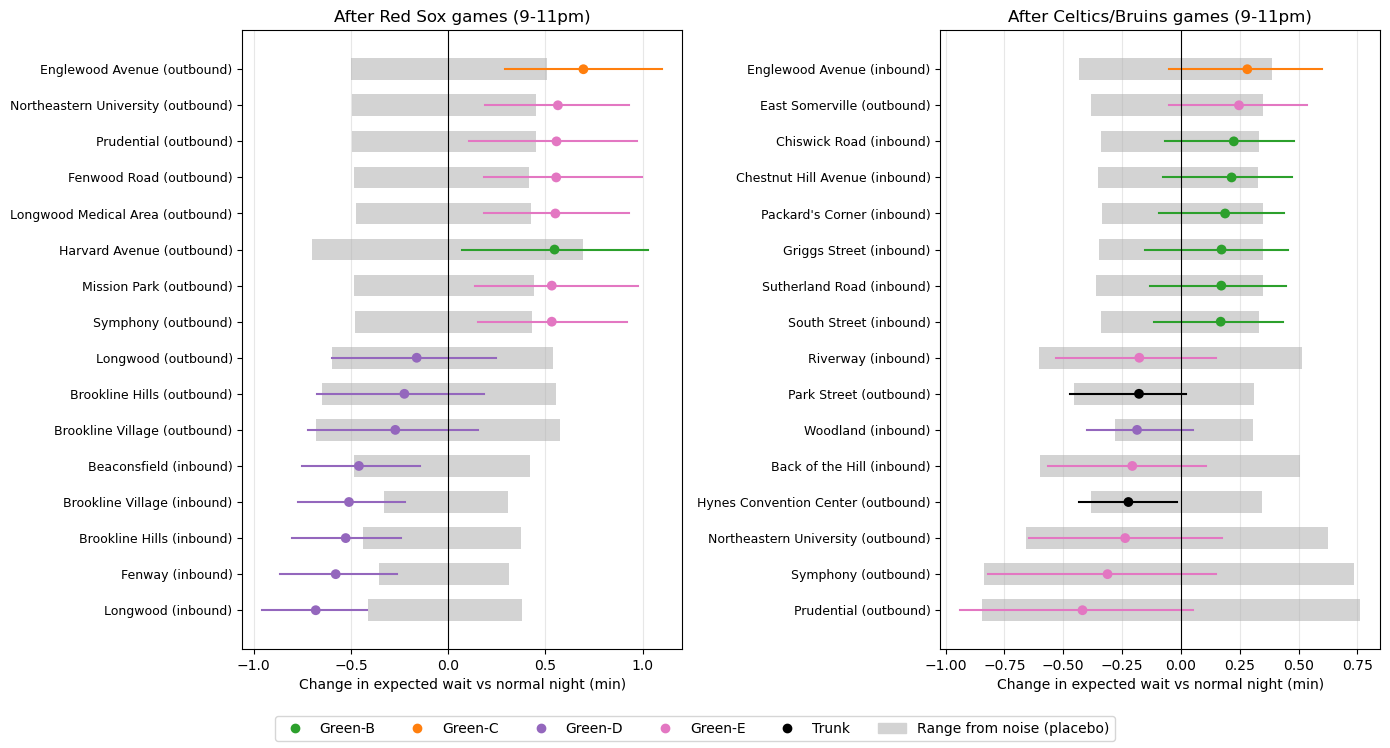

In [15]:
colors = {'Green-B': 'tab:green', 'Green-C': 'tab:orange', 'Green-D': 'tab:purple', 'Green-E': 'tab:pink', 'Trunk': 'black'}

fig, axes = plt.subplots(1, 2, figsize=(14, 7.5))
for ax, v, title in [(axes[0], 'fenway', 'After Red Sox games (9-11pm)'),
                     (axes[1], 'garden', 'After Celtics/Bruins games (9-11pm)')]:
    show = pd.concat([changes[v].head(8), changes[v].tail(8)])
    y = np.arange(len(show))
    ax.barh(y, show['noise_high'] - show['noise_low'], left=show['noise_low'], color='lightgray', height=0.6)
    for i, r in enumerate(show.itertuples()):
        ax.plot([r.ci_low, r.ci_high], [i, i], color=colors[r.branch])
        ax.scatter(r.change, i, color=colors[r.branch], edgecolor='black' if r.affected else 'none', s=50, zorder=3)
    ax.axvline(0, color='black', linewidth=0.8)
    ax.set_yticks(y)
    ax.set_yticklabels(show['label'], fontsize=9)
    ax.set_xlabel('Change in expected wait vs normal night (min)')
    ax.set_title(title)
    ax.grid(axis='x', alpha=0.3)
handles = [plt.Line2D([], [], marker='o', linestyle='', color=c, label=b) for b, c in colors.items()]
handles.append(plt.Rectangle((0, 0), 1, 1, color='lightgray', label='Range from noise (placebo)'))
fig.legend(handles=handles, loc='lower center', ncol=6)
plt.tight_layout(rect=(0, 0.05, 1, 1))
plt.savefig('figures/station_changes_after_games.png')
plt.show()

In [16]:
cols = ['label', 'branch', 'normal_wait', 'change', 'ci_low', 'ci_high', 'pct_change', 'p_value', 'q_value']
fenway = changes['fenway']
fenway.loc[fenway['affected'], cols].round(2)

,label,branch,normal_wait,change,ci_low,ci_high,pct_change,p_value,q_value


## Why do some stations get worse?
For a few of the stations that changed most after Red Sox games: trains per hour and how uneven the gaps are (**irregularity** = standard deviation ÷ mean of the gaps; higher means more bunching).

In [17]:
hourly['cv'] = np.sqrt((hourly['sum_h2'] / hourly['trains'] - (hourly['sum_h'] / hourly['trains']) ** 2).clip(lower=0)) \
               / (hourly['sum_h'] / hourly['trains'])
game_dates, normal_dates = get_dates('fenway')
check = hourly[hourly['hour'].isin([21, 22])].copy()
check['night'] = np.where(check['service_date'].isin(game_dates), 'game',
                          np.where(check['service_date'].isin(normal_dates), 'normal', None))
check = check.dropna(subset=['night'])
stations = [('place-fenwy', 1), ('place-longw', 1), ('place-harvd', 0), ('place-bucen', 0), ('place-engav', 0), ('place-lech', 0)]
rows = []
for st, d in stations:
    s = check[(check['parent_station'] == st) & (check['direction_id'] == d)]
    means = s.groupby('night')[['trains', 'cv', 'wait']].mean()
    rows.append({'station': names[st] + (' (inbound)' if d else ' (outbound)'), 'branch': branch[st],
                 'trains game': means.loc['game', 'trains'], 'trains normal': means.loc['normal', 'trains'],
                 'irregularity game': means.loc['game', 'cv'], 'irregularity normal': means.loc['normal', 'cv']})
pd.DataFrame(rows).round(2)

,station,branch,trains game,trains normal,irregularity game,irregularity normal
0,Fenway (inbound),Green-D,6.06,5.13,0.47,0.37
1,Longwood (inbound),Green-D,5.89,5.03,0.45,0.35
2,Harvard Avenue (outbound),Green-B,5.91,6.02,0.57,0.51
3,Boston University Central (outbound),Green-B,5.60,5.72,0.52,0.47
4,Englewood Avenue (outbound),Green-C,6.20,6.50,0.62,0.56
5,Lechmere (outbound),Trunk,11.02,11.51,0.60,0.60


## Demand: gated station entries
The headway data only shows trains. To see the **crowd**, we use MBTA gated station entries: people tapping through the fare gates, counted every 30 minutes.

Limits:
- Only stations with gates. Kenmore and North Station are included, Fenway (D branch) isn't.
- Only **entries**, so we see fans leaving a game, not arriving.
- At stations with more than one line, the MBTA splits entries by line. We keep the Green Line share.
- Gates are sometimes held open at big events, but the surge below shows they were counting.

In [18]:
gse = pd.read_csv('data/GSE_2024.csv', parse_dates=['service_date'])
gse = gse[gse['route_or_line'].str.contains('Green')].rename(columns={'stop_id': 'parent_station'})

# time_period looks like '(21:30:00)'. After-midnight periods become 24, 25 like in the headway data
time = gse['time_period'].str.strip('()')
gse['hour'] = time.str[:2].astype(int)
gse.loc[gse['hour'] < 3, 'hour'] += 24
gse['half_hour'] = gse['hour'] + time.str[3:5].astype(int) / 60

# drop the same shutdown station-days as the headway data
gse = gse.merge(bad_days, on=['parent_station', 'service_date'], how='left')
gse = gse[gse['bad'].isna()].drop(columns='bad')

print('rows:', len(gse))
print('gated Green Line stations:', gse['parent_station'].nunique(), ' days:', gse['service_date'].nunique())
gse.groupby('station_name')['gated_entries'].sum().sort_values(ascending=False).head(10).round(0)

FileNotFoundError: [Errno 2] No such file or directory: 'data/GSE_2024.csv'

## Plot: people entering the station on game nights
Entries every 30 minutes, with 95% confidence bands.

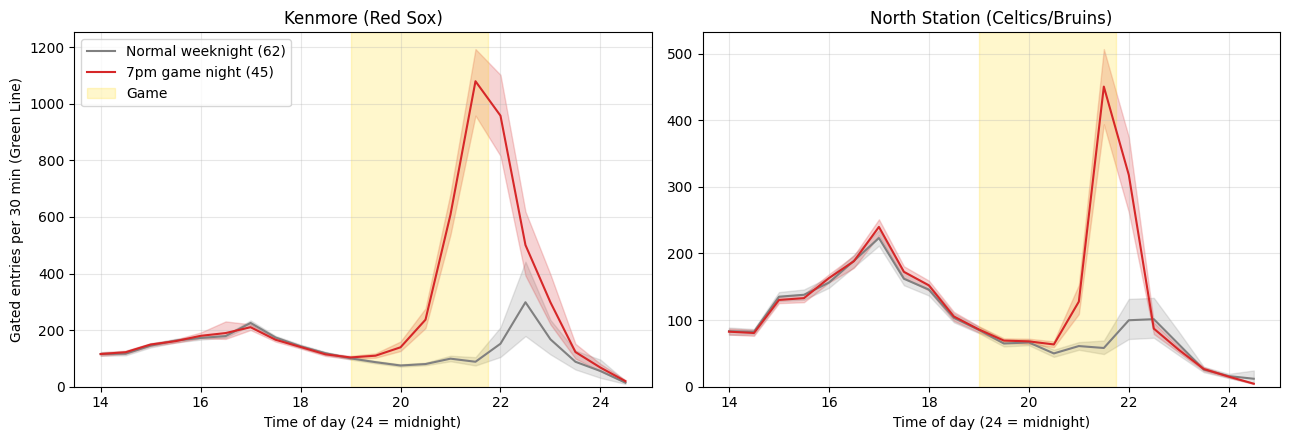

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, (station, venue, title) in zip(axes, [('place-kencl', 'fenway', 'Kenmore (Red Sox)'),
                                               ('place-north', 'garden', 'North Station (Celtics/Bruins)')]):
    game_dates, normal_dates = get_dates(venue)
    s = gse[(gse['parent_station'] == station) & (gse['half_hour'] >= 14) & (gse['half_hour'] <= 24.5)]
    for dates, color, label in [(normal_dates, 'gray', f'Normal weeknight ({len(normal_dates)})'),
                                (game_dates, 'tab:red', f'7pm game night ({len(game_dates)})')]:
        times, mean, low, high = by_hour_with_ci(s, 'gated_entries', dates, time_col='half_hour')
        ax.plot(times, mean, color=color, label=label)
        ax.fill_between(times, low, high, color=color, alpha=0.2)
    ax.axvspan(19, 21.75, color='gold', alpha=0.2, label='Game')
    ax.set_title(title)
    ax.set_xlabel('Time of day (24 = midnight)')
    ax.set_xticks(range(14, 25, 2))
    ax.set_ylim(bottom=0)
    ax.grid(alpha=0.3)
axes[0].set_ylabel('Gated entries per 30 min (Green Line)')
axes[0].legend(loc='upper left')
plt.tight_layout()
plt.savefig('figures/ridership_game_nights.png')
plt.show()

## Riders per train
People entering per hour ÷ trains leaving per hour. If riders jump but trains don't, each train gets more crowded.

In [ ]:
trains_per_hour = hourly.groupby(['parent_station', 'service_date', 'hour'])['trains'].sum().rename('trains').reset_index()
entries_per_hour = gse.groupby(['parent_station', 'service_date', 'hour'])['gated_entries'].sum().rename('entries').reset_index()
crowd = entries_per_hour.merge(trains_per_hour, on=['parent_station', 'service_date', 'hour'])
crowd['riders_per_train'] = crowd['entries'] / crowd['trains']

rows = []
for station, name, venue in [('place-kencl', 'Kenmore', 'fenway'), ('place-north', 'North Station', 'garden')]:
    game_dates, normal_dates = get_dates(venue)
    s = crowd[(crowd['parent_station'] == station) & crowd['hour'].isin([21, 22])]
    for night, dates in [('game', game_dates), ('normal', normal_dates)]:
        n = s[s['service_date'].isin(dates)]
        rows.append({'station': name, 'night': night, 'entries per hour': n['entries'].mean(),
                     'trains per hour': n['trains'].mean(), 'riders per train': n['riders_per_train'].mean()})
crowding = pd.DataFrame(rows)
crowding.round(1)

,station,night,entries per hour,trains per hour,riders per train
0,Kenmore,game,1573.7,32.7,48.7
1,Kenmore,normal,319.0,31.9,10.1
2,North Station,game,490.9,25.2,20.8
3,North Station,normal,158.4,24.9,6.6


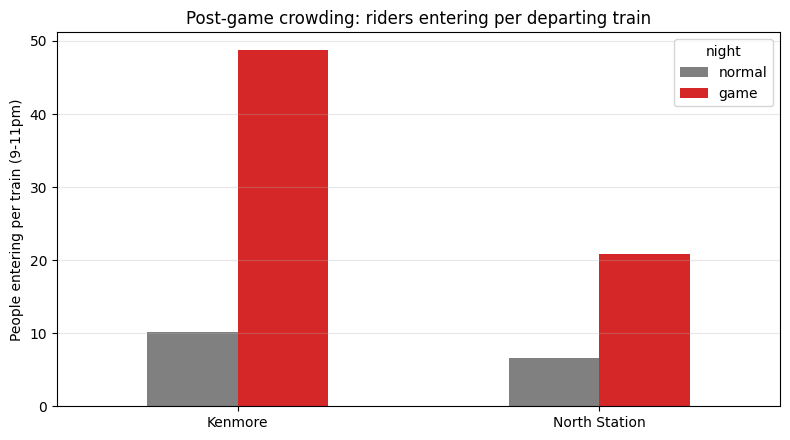

In [ ]:
table = crowding.pivot(index='station', columns='night', values='riders per train')[['normal', 'game']]
table.plot(kind='bar', figsize=(8, 4.5), color=['gray', 'tab:red'], rot=0)
plt.ylabel('People entering per train (9-11pm)')
plt.xlabel('')
plt.title('Post-game crowding: riders entering per departing train')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('figures/riders_per_train.png')
plt.show()

## Model: linear regression for the delay a game causes
This is our one model. We fit it separately for **every station and direction** (about 130), using every home game:

$$\text{wait} = \text{hour type} + \text{month} + \text{holiday} + \text{rain} + \text{snow} + \text{temperature} + \text{Fenway game term} + \text{Garden game term}$$

- **hour type**: hour of day, split into weekday and weekend (e.g. 9pm weekday). Accounts for the normal schedule.
- **month, holiday, rain, snow, temperature**: account for other things that change service.
- **game terms** (pre, during or post, for night or day games, at each venue): the **extra minutes of wait compared with a normal day at the same hour, in the same weather**. This is what we want.

**Why linear regression:** it answers our goal directly, giving a delay in minutes with a confidence interval, and it's easy to explain.

**Why every station:** picking stations because they looked affected and then testing them on the same data is circular. Fitting every station avoids that.

Details: standard errors are clustered by day (hours on the same day are related), and hour types with under 20 days of data are dropped.

In [ ]:
formula = ('wait ~ C(hour_type) + C(month) + holiday + rain + snow + temperature_f'
           ' + C(fenway_term, Treatment("none")) + C(garden_term, Treatment("none"))')
no_game_formula = 'wait ~ C(hour_type) + C(month) + holiday + rain + snow + temperature_f'

def station_data(station, direction):
    s = hourly[(hourly['parent_station'] == station) & (hourly['direction_id'] == direction)].dropna(subset=['temperature_f']).copy()
    s['weekend'] = (~s['weekday']).astype(int)
    s['hour_type'] = s['hour'].astype(str) + np.where(s['weekend'] == 1, '_weekend', '_weekday')
    days_per_cell = s.groupby('hour_type')['service_date'].transform('nunique')
    return s[days_per_cell >= 20].reset_index(drop=True)

def term_name(venue, term):
    return f'C({venue}_term, Treatment("none"))[T.{term}]'

results = []
for (station, direction), _ in hourly.groupby(['parent_station', 'direction_id']):
    s = station_data(station, direction)
    if s['service_date'].nunique() < 100:
        continue
    model = smf.ols(formula, data=s).fit(cov_type='cluster', cov_kwds={'groups': s['service_date'].dt.dayofyear})
    param_names = list(model.params.index)
    ci = model.conf_int()
    for v in ['fenway', 'garden']:
        game_cols = [n for n in param_names if n.startswith(f'C({v}_term')]
        post_night, post_day = term_name(v, 'post_night'), term_name(v, 'post_day')
        if post_night not in param_names:
            continue
        row = {'station': station, 'direction_id': direction, 'venue': v,
               'effect': model.params[post_night], 'ci_low': ci.loc[post_night, 0], 'ci_high': ci.loc[post_night, 1],
               'p_value': model.pvalues[post_night],
               'normal_wait': s.loc[s['hour'].isin([21, 22]) & (s[v + '_term'] == 'none'), 'wait'].mean()}
        # F-test 1: are ALL of this venue's game terms zero? (does the game matter at all here?)
        R = np.zeros((len(game_cols), len(param_names)))
        for k, col in enumerate(game_cols):
            R[k, param_names.index(col)] = 1
        f = model.wald_test(R, use_f=True, scalar=True)
        row['F_all_game_terms'], row['p_F_all'] = f.statistic, f.pvalue
        # F-test 2: is the post-game effect the same for night and day games?
        if post_day in param_names:
            r = np.zeros((1, len(param_names)))
            r[0, param_names.index(post_night)], r[0, param_names.index(post_day)] = 1, -1
            f2 = model.wald_test(r, use_f=True, scalar=True)
            row['F_night_vs_day'], row['p_night_vs_day'] = f2.statistic, f2.pvalue
        results.append(row)

results = pd.DataFrame(results)
results['stop_name'] = results['station'].map(names)
results['branch'] = results['station'].map(branch)
results['label'] = results['stop_name'] + np.where(results['direction_id'] == 1, ' (inbound)', ' (outbound)')
results['pct_effect'] = 100 * results['effect'] / results['normal_wait']
# Benjamini-Hochberg correction, separately for each venue (we test ~130 stations per venue)
for v in ['fenway', 'garden']:
    m = results['venue'] == v
    results.loc[m, 'q_value'] = multipletests(results.loc[m, 'p_value'], method='fdr_bh')[1]
    results.loc[m, 'q_F_all'] = multipletests(results.loc[m, 'p_F_all'], method='fdr_bh')[1]
print('station-directions fit:', results.groupby('venue').size().to_dict())

station-directions fit: {'fenway': 128, 'garden': 128}


## Tests: p-values, F-tests and the multiple-testing correction
For each station we report three tests:

| Test | Question it answers | Null hypothesis |
|---|---|---|
| **t-test** (p-value) on the post-game night effect | Do waits change after night games? | effect = 0 |
| **F-test** on all game terms together | Does this venue's game matter at all, at any time? | all 6 game terms = 0 |
| **F-test** night vs day | Is the post-game effect different for night and day games? | night effect = day effect |

A **t-test** checks one coefficient. An **F-test** checks several at once, or whether two are equal. With about 130 stations, we use the **Benjamini-Hochberg correction** again: a result counts as **significant if q < 0.05**.

In [ ]:
for v, venue_name in [('fenway', 'Red Sox'), ('garden', 'Celtics/Bruins')]:
    r = results[results['venue'] == v]
    print(f"{venue_name}: post-game night effect significant (q < 0.05) at {(r['q_value'] < 0.05).sum()} of {len(r)} station-directions "
          f"({((r['q_value'] < 0.05) & (r['effect'] > 0)).sum()} longer waits, {((r['q_value'] < 0.05) & (r['effect'] < 0)).sum()} shorter)")
    print(f"   F-test, any game effect (q < 0.05): {(r['q_F_all'] < 0.05).sum()} of {len(r)}")

cols = ['label', 'branch', 'venue', 'normal_wait', 'effect', 'ci_low', 'ci_high', 'p_value', 'q_value', 'p_F_all', 'p_night_vs_day']
venue_rows = results['station'].isin(['place-kencl', 'place-fenwy', 'place-north']) & (
    ((results['venue'] == 'fenway') & (results['station'] != 'place-north')) | ((results['venue'] == 'garden') & (results['station'] == 'place-north')))
print('\nVenue stations:')
display(results.loc[venue_rows, cols].round(3))
print('Significant stations (q < 0.05):')
display(results.loc[results['q_value'] < 0.05, cols].sort_values(['venue', 'effect']).round(3))

Red Sox: post-game night effect significant (q < 0.05) at 46 of 128 station-directions (41 longer waits, 5 shorter)
   F-test, any game effect (q < 0.05): 47 of 128
Celtics/Bruins: post-game night effect significant (q < 0.05) at 0 of 128 station-directions (0 longer waits, 0 shorter)
   F-test, any game effect (q < 0.05): 4 of 128

Venue stations:


,label,branch,venue,normal_wait,effect,ci_low,ci_high,p_value,q_value,p_F_all,p_night_vs_day
112,Fenway (outbound),Green-D,fenway,6.728,0.140,-0.222,0.502,0.450,0.505,0.000,0.002
114,Fenway (inbound),Green-D,fenway,6.838,-0.337,-0.645,-0.029,0.032,0.077,0.000,0.494
144,Kenmore (outbound),Trunk,fenway,2.843,0.137,0.010,0.264,0.035,0.082,0.024,0.031
146,Kenmore (inbound),Trunk,fenway,2.950,-0.134,-0.238,-0.030,0.011,0.039,0.009,0.334
185,North Station (outbound),Trunk,garden,3.467,-0.142,-0.411,0.128,0.302,0.712,0.362,0.783
187,North Station (inbound),Trunk,garden,4.021,-0.095,-0.272,0.083,0.296,0.712,0.570,0.939


Significant stations (q < 0.05):


,label,branch,venue,normal_wait,effect,ci_low,ci_high,p_value,q_value,p_F_all,p_night_vs_day
162,Longwood (inbound),Green-D,fenway,6.836,-0.444,-0.686,-0.202,0.000,0.003,0.000,0.772
50,Brookline Hills (inbound),Green-D,fenway,6.834,-0.399,-0.672,-0.125,0.004,0.019,0.000,0.352
66,Brookline Village (inbound),Green-D,fenway,6.808,-0.393,-0.653,-0.132,0.003,0.015,0.000,0.600
26,Beaconsfield (inbound),Green-D,fenway,6.828,-0.319,-0.581,-0.058,0.017,0.048,0.000,0.078
146,Kenmore (inbound),Trunk,fenway,2.950,-0.134,-0.238,-0.030,0.011,0.039,0.009,0.334
40,Boylston (outbound),Trunk,fenway,2.049,0.127,0.024,0.231,0.016,0.047,0.014,0.096
8,Arlington (outbound),Trunk,fenway,2.112,0.132,0.027,0.238,0.014,0.044,0.005,0.044
140,Hynes Convention Center (outbound),Trunk,fenway,2.858,0.213,0.066,0.361,0.005,0.020,0.001,0.243
150,Kent Street (inbound),Green-C,fenway,5.569,0.320,0.071,0.569,0.012,0.040,0.189,0.187
216,Science Park/West End (outbound),Trunk,fenway,3.401,0.322,0.092,0.552,0.006,0.024,0.121,0.312


## Which areas are most affected?
Our goal asks about areas, not just single stations, so here is the model's post-game night effect averaged by branch and direction, with how many stations in each group are significant.

In [ ]:
area = results.copy()
area['direction'] = np.where(area['direction_id'] == 1, 'inbound', 'outbound')
area['significant'] = area['q_value'] < 0.05
area_summary = (area.groupby(['venue', 'branch', 'direction'])
                .agg(stations=('effect', 'size'), mean_effect_min=('effect', 'mean'),
                     mean_pct=('pct_effect', 'mean'), significant=('significant', 'sum'))
                .round(2))
print('Night vs day F-test: p < 0.05 at', (results['p_night_vs_day'] < 0.05).sum(), 'of', results['p_night_vs_day'].notna().sum(), 'station-directions')
area_summary

Night vs day F-test: p < 0.05 at 18 of 256 station-directions


stations  mean_effect_min  mean_pct  significant
venue  branch  direction                                                  
fenway Green-B inbound          15             0.10      1.64            0
               outbound         15             0.64      9.43           15
       Green-C inbound          12             0.30      5.41            5
               outbound         12             0.58      9.15           12
       Green-D inbound          12            -0.03     -0.49            4
               outbound         12             0.35      4.93            2
       Green-E inbound          14             0.14      2.26            0
               outbound         14             0.25      4.23            0
       Trunk   inbound          11             0.11      2.81            2
               outbound         11             0.20      6.92            6
garden Green-B inbound          15            -0.05     -0.72            0
               outbound         15            -0.14     -2.04            0
       Green-C inbound          12            -0.08     -1.46            0
               outbound         12            -0.09     -1.41            0
       Green-D inbound          12            -0.16     -2.35            0
               outbound         12            -0.05     -0.78            0
       Green-E inbound          14             0.16      2.76            0
               outbound         14             0.14      2.52            0
       Trunk   inbound          11            -0.07     -2.57            0
               outbound         11            -0.11     -3.96            0

## Plot: extra wait after night games, by station
The model's post-game night effect for every station that's significant (q < 0.05), plus the venue stations.
- **Filled dots**: significant after the correction. **Hollow dots**: not significant.
- **Lines**: 95% confidence intervals. Colors are the branch.

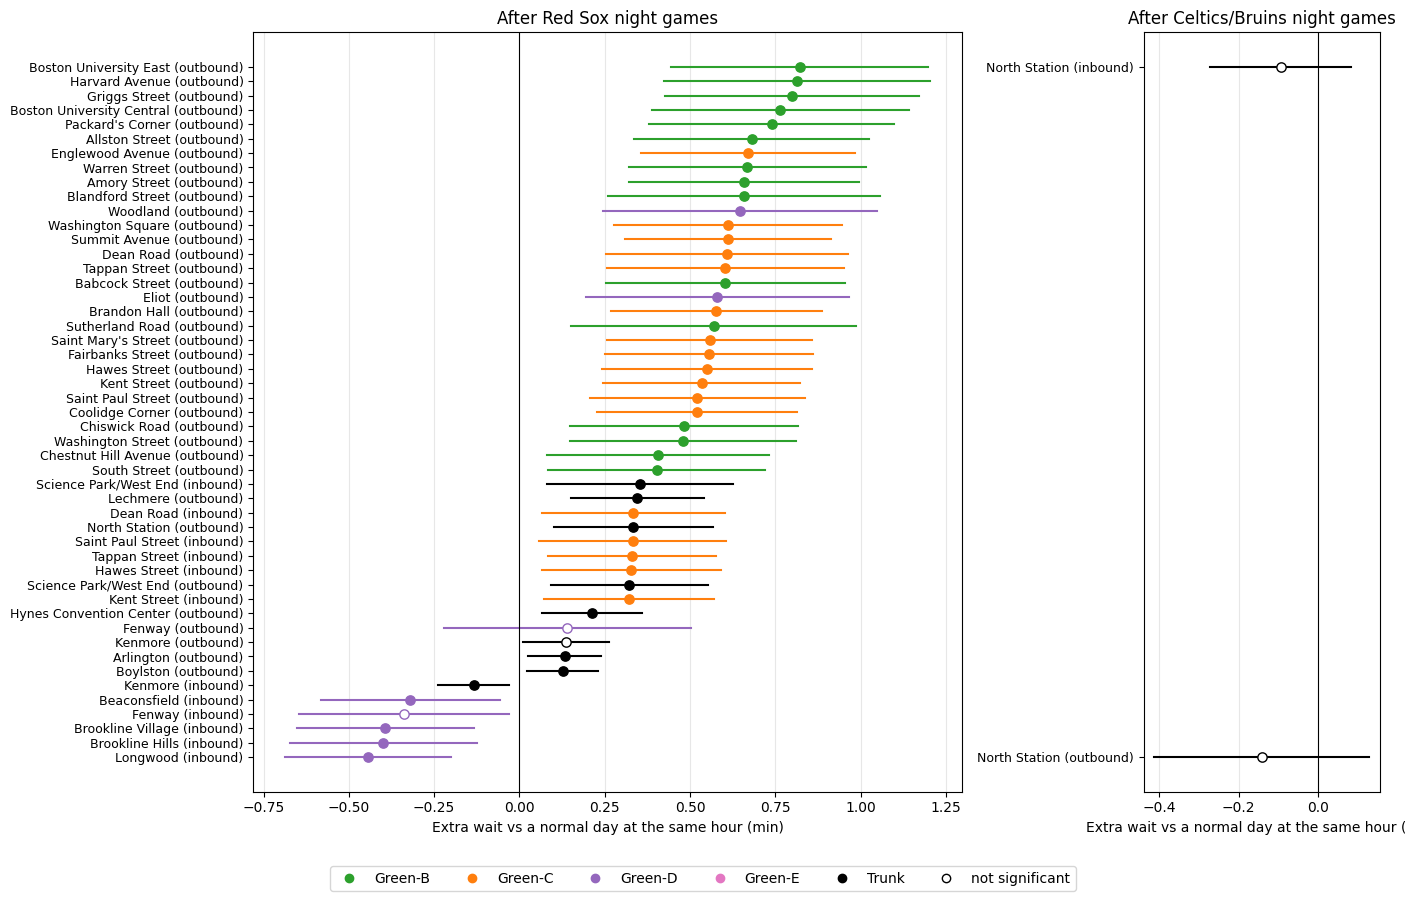

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 9), gridspec_kw={'width_ratios': [3, 1]})
for ax, v, venue_station, title in [(axes[0], 'fenway', ['place-kencl', 'place-fenwy'], 'After Red Sox night games'),
                                    (axes[1], 'garden', ['place-north'], 'After Celtics/Bruins night games')]:
    r = results[(results['venue'] == v) & ((results['q_value'] < 0.05) | results['station'].isin(venue_station))].sort_values('effect')
    y = np.arange(len(r))
    for i, row in enumerate(r.itertuples()):
        c = colors[row.branch]
        ax.plot([row.ci_low, row.ci_high], [i, i], color=c)
        ax.scatter(row.effect, i, s=45, zorder=3, edgecolor=c, color=c if row.q_value < 0.05 else 'white')
    ax.axvline(0, color='black', linewidth=0.8)
    ax.set_yticks(y)
    ax.set_yticklabels(r['label'], fontsize=9)
    ax.set_xlabel('Extra wait vs a normal day at the same hour (min)')
    ax.set_title(title)
    ax.grid(axis='x', alpha=0.3)
handles = [plt.Line2D([], [], marker='o', linestyle='', color=c, label=b) for b, c in colors.items()]
handles.append(plt.Line2D([], [], marker='o', linestyle='', color='white', markeredgecolor='black', label='not significant'))
fig.legend(handles=handles, loc='lower center', ncol=6)
plt.tight_layout(rect=(0, 0.05, 1, 1))
plt.savefig('figures/regression_game_effects.png')
plt.show()

## Testing the model on days it hasn't seen
We split the **days** into 5 groups, fit the model on 4, and predict the 5th, at every station. Whole days are held out, because hours on the same day are too similar to split up.

We compare our model with two simpler baselines:
1. **Historical average**: the normal wait for that hour
2. **Our model without the game terms** (still has weather, holidays, month)
3. **Our model**
4. **Random forest**: same inputs (hour, weekend, month, holiday, weather, game windows), to check whether a flexible nonlinear model finds something the linear one misses

**Score: mean absolute error (MAE)**, the average size of the miss, in minutes:

$$\text{MAE} = \frac{1}{n}\sum_{i=1}^{n} \left|\,\text{actual}_i - \text{predicted}_i\,\right|$$

Example: misses of 0.5, 1.0 and 0.3 min give MAE = 0.6 min. **Lower is better.** We look at post-game night hours, where a game effect would show up. This takes a few minutes to run.

**Why this test matters even if the gain is small:** a game effect can be *statistically significant* (we're confident it isn't zero) and still be *small compared with normal night-to-night ups and downs*. The test tells us which one we have.

In [ ]:
from sklearn.ensemble import RandomForestRegressor
rf_features = ['hour', 'weekend', 'month', 'holiday', 'rain', 'snow', 'temperature_f']

def fold_of(dates):
    # assign each day to one of 5 folds at random
    unique_days = np.sort(dates.unique())
    fold = pd.Series(rng.permutation(len(unique_days)) % 5, index=unique_days)
    return dates.map(fold).to_numpy()

scores = []
for (station, direction), _ in hourly.groupby(['parent_station', 'direction_id']):
    s = station_data(station, direction)
    if s['service_date'].nunique() < 100:
        continue
    s['fold'] = fold_of(s['service_date'])
    X = pd.get_dummies(s[rf_features + ['fenway_term', 'garden_term']], columns=['fenway_term', 'garden_term']).fillna(0)
    pred = {k: np.full(len(s), np.nan) for k in ['Historical average', 'Model without game terms', 'Our model', 'Random forest']}
    for k in range(5):
        train, test = s[s['fold'] != k], s[s['fold'] == k]
        avg = train.groupby('hour_type')['wait'].mean().rename('avg')
        pred['Historical average'][test.index] = test[['hour_type']].merge(avg, on='hour_type', how='left')['avg'].to_numpy()
        rf = RandomForestRegressor(n_estimators=100, min_samples_leaf=20, n_jobs=-1, random_state=506)
        pred['Random forest'][test.index] = rf.fit(X.loc[train.index], train['wait']).predict(X.loc[test.index])
        try:
            pred['Model without game terms'][test.index] = smf.ols(no_game_formula, data=train).fit().predict(test)
            pred['Our model'][test.index] = smf.ols(formula, data=train).fit().predict(test)
        except Exception:
            pass   # a test fold with a category the training folds never saw; those rows are skipped
    post_night = ((s['fenway_term'] == 'post_night') | (s['garden_term'] == 'post_night')).to_numpy()
    for name, p in pred.items():
        err = np.abs(s['wait'].to_numpy() - p)
        scores.append({'station': station, 'direction_id': direction, 'model': name,
                       'abs_err_all': np.nansum(err), 'n_all': np.sum(~np.isnan(err)),
                       'abs_err_post': np.nansum(err[post_night]), 'n_post': np.sum(~np.isnan(err[post_night]))})
scores = pd.DataFrame(scores)

summary = scores.groupby('model')[['abs_err_all', 'n_all', 'abs_err_post', 'n_post']].sum()
summary['MAE all hours'] = summary['abs_err_all'] / summary['n_all']
summary['MAE post-game night'] = summary['abs_err_post'] / summary['n_post']
summary = summary.loc[['Historical average', 'Model without game terms', 'Our model', 'Random forest'], ['MAE all hours', 'MAE post-game night']]
summary.round(3)

,MAE all hours,MAE post-game night
model,,
Historical average,0.927,0.964
Model without game terms,0.918,0.960
Our model,0.919,0.963


model
Historical average          0.760
Model without game terms    0.760
Our model                   0.756
Name: MAE post-game night, venue stations, dtype: float64


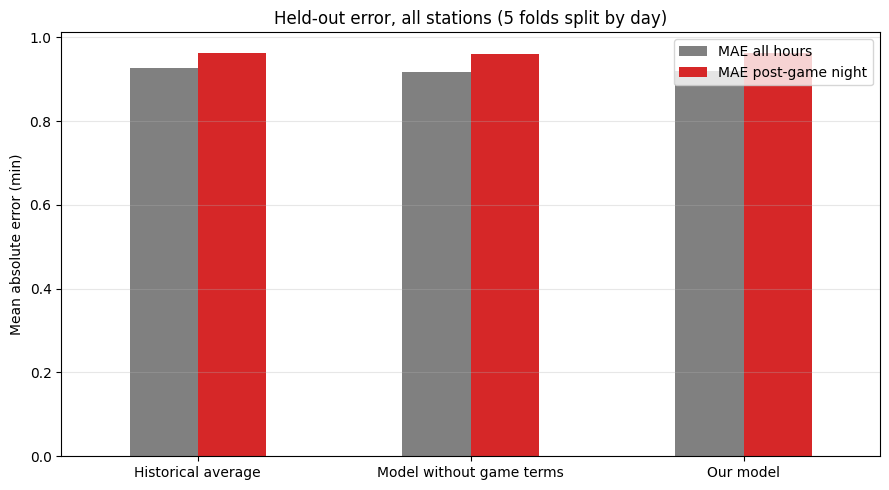

In [ ]:
# MAE at the venue stations only, where the effects are biggest
venue = scores[scores['station'].isin(['place-kencl', 'place-fenwy', 'place-north'])]
venue_summary = venue.groupby('model')[['abs_err_post', 'n_post']].sum()
venue_summary = (venue_summary['abs_err_post'] / venue_summary['n_post']).rename('MAE post-game night, venue stations')
print(venue_summary.loc[['Historical average', 'Model without game terms', 'Our model', 'Random forest']].round(3))

summary.plot(kind='bar', figsize=(9, 5), color=['gray', 'tab:red'], rot=0)
plt.ylabel('Mean absolute error (min)')
plt.xlabel('')
plt.title('Held-out error, all stations (5 folds split by day)')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('figures/model_test_error.png')
plt.show()

## Random forest vs linear regression
| Model | MAE all hours | MAE post-game night | MAE post-game night, venue stations |
|---|---|---|---|
| Linear regression (our model) | 0.919 | 0.966 | 0.760 |
| Random forest | 0.914 | 0.954 | 0.752 |

The random forest predicts slightly better, but only by about 0.01 min (under 1 second), and neither model is much better than the historical-average baseline. Both models hit the same floor: most of the night-to-night variation in wait isn't explained by games, weather or the schedule.

**Why we still use linear regression:** our goal is to *estimate how much delay a game causes*, not to forecast one night's wait.
- **It gives the answer directly.** Each game coefficient is the extra minutes of wait vs a normal day at the same hour and weather, with a confidence interval. A random forest has no coefficient, only feature importances, which say a feature is used, not how many minutes it adds or in which direction.
- **It supports the tests we need.** t-tests, F-tests, clustered standard errors and the Benjamini-Hochberg correction all come from the regression. A random forest has no p-values, so we couldn't say which stations are significantly affected.
- **The forest's edge is tiny and not clearly about games.** It can fit interactions the linear model leaves out (e.g. temperature x hour), which likely explains most of the gain. Game hours are a small share of the data, so a forest isn't built to isolate their effect from everything else.
- **Simpler and easier to defend.** With a gain of under a second, the interpretable model wins.


## Limitations
- **Expected wait assumes riders arrive at random.** Late at night, with few trains, some riders time their arrival, so we may overstate waits there.
- **We measure waiting for a train, not slower trips.** Crowded trains take longer to board, which can slow trips without changing the gaps between trains. The MBTA travel time data would show this.
- **Gated entries only count people entering**, at gated stations only (Fenway isn't included).
- **Other events**: concerts at Fenway and TD Garden aren't labeled, so a few "normal nights" may have had crowds. That would make our effects look *smaller*, not bigger.
- **Weather is for one point in Boston**, not each station.

## What we found

**1. Games bring huge crowds.**
After a 7pm game, people entering per hour (9-11pm):

| Station | Normal night | Game night |
|---|---|---|
| Kenmore (Red Sox) | 310 | 1,570 (5x) |
| North Station (Celtics/Bruins) | 150 | 490 (3x) |

**2. The MBTA mostly doesn't add trains, so trains get packed.**
Trains per hour barely change, so riders entering per train go from **10 to 49** at Kenmore and from **6 to 21** at North Station.

**3. After Red Sox night games, the D branch gets better...**
The MBTA adds about 1 inbound D branch train per hour. Our model (all games, controlling for weather, holidays and the schedule) finds inbound waits **0.3-0.45 min shorter** at Longwood, Brookline Hills, Brookline Village and Beaconsfield, and 0.13 min shorter at Kenmore (all q < 0.05).

**4. ...and the B and C branches get worse.**
These are the most affected areas. Westbound (outbound) waits go up on **every** B and C branch station:

| Area (after Red Sox night games) | Average change | Significant stations |
|---|---|---|
| B branch outbound | +0.64 min (+9%) | 15 of 15 |
| C branch outbound | +0.58 min (+9%) | 12 of 12 |
| Trunk outbound | +0.20 min (+7%) | 6 of 11 |
| C branch inbound | +0.30 min (+5%) | 5 of 12 |
| E branch | +0.14 to +0.25 min | 0 of 28 |

Trains there also come a bit less often (Englewood Ave outbound: 6.5 to 6.2 per hour) and are more bunched (irregularity 0.56 to 0.62).

In total **46 of 128** station-directions are significant after the correction (41 longer waits, 5 shorter). The F-test for "does the Red Sox game matter at all" is significant at 47 of 128.

**5. Celtics/Bruins games: crowded trains, no delays.**
No station is significant (0 of 128), and the F-test finds an effect at only 4 of 128. At North Station the model rules out any delay bigger than about 8 seconds. North Station already runs about 25 trains an hour, so the extra riders fit on the trains already coming.

**6. Night vs day games are mostly similar.** The F-test finds a difference at only 18 of 256 station-directions (about 13 would by chance).

**7. The effects are real but small compared with normal variation.**
On held-out days, adding the game terms doesn't improve predictions across all stations (post-game MAE 0.960 without vs 0.963 with), and only slightly at the venue stations (0.760 to 0.756). A shift of about half a minute is clear when averaged over a whole season, but on any one night it's smaller than the usual ups and downs (MAE about 0.96 min), so it doesn't help predict a single night.

**What this means for our hypothesis**
We expected games to cause delays near the venues. Instead:
- games **pack the trains** at the venue stations with 3-5x the usual riders,
- after Red Sox night games the D branch gets **extra trains and shorter waits**,
- while riders heading **west on the B and C branches wait about 9% longer**. A likely reason is that trains and operators are moved to the D branch, but we haven't tested that yet.